# 02. Exploratory Data Analysis (EDA): Delivery Lateness & Customer Satisfaction

This notebook conducts a comprehensive exploratory data analysis of the Brazilian Olist E-Commerce dataset (~100k orders). It generates the full suite of **7 core operational and customer satisfaction charts**, answering critical operational questions:

1. **Overall Late Rate:** What is the platform-wide baseline delivery lateness rate?
2. **Geographic Variance:** Which destination states experience the highest lateness?
3. **Distance Elasticity:** How does transit distance affect late delivery probability?
4. **Seasonality & Shocks:** What macro disruptions (Black Friday, carrier strikes) impacted logistics over time?
5. **The Satisfaction Collapse:** How do review scores shift when deliveries are on-time vs. late?
6. **Commercial Drag:** How do freight-to-price ratios influence customer review scores?
7. **Feature Correlations:** What are the pairwise Spearman correlations between operational, commercial, and sentiment metrics?


## 1. Environment Setup & Data Loading

We ingest the clean analytical master dataset (`order_master`) from `olist.duckdb`. The table contains 95,795 clean, delivered orders with pre-calculated geodesic transit distances, temporal milestones, and customer review scores.


In [1]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Visual style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['figure.titlesize'] = 15
plt.rcParams['figure.titleweight'] = 'bold'

# Connect to DuckDB and load cleaned master table
import os
db_path = 'olist.duckdb' if os.path.exists('olist.duckdb') else '../olist.duckdb'
con = duckdb.connect(db_path)
df = con.execute("SELECT * FROM order_master").df()
con.close()

print(f"Loaded order_master successfully: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head(3)


Loaded order_master successfully: 95,795 rows, 47 columns


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,is_late,days_late,...,review_score,low_review,weight_capped,freight_ratio_capped,volume_capped,log_weight,log_volume,log_price,log_freight,log_distance
0,677c865b89aa97e7dbeb4bfbb50bbcfd,529d3f46584a8fa9027777a9c7d5a1fc,delivered,2018-08-14 23:08:33,2018-08-14 23:24:13,2018-08-23 12:51:00,2018-08-24 23:42:42,2018-08-31,0,-6.01,...,5,0,300.0,0.0925,4256.0,5.707110,8.356320,4.454347,2.181547,2.479056
1,97e11582eb8cdd7b83e35a4243d81f79,119e936a72d10c6ea12ab6129ffd9a79,delivered,2017-12-15 14:35:37,2017-12-15 14:52:53,2017-12-21 20:45:07,2018-01-12 00:13:38,2018-01-15,0,-2.99,...,5,0,250.0,0.1543,1584.0,5.525453,7.368340,5.141079,3.303952,7.939059
2,46d2d651f006b9b9440d1aa37d89c894,47fc7efce86cec4a5076958ff5ea7df4,delivered,2018-07-23 16:53:28,2018-07-25 02:35:15,2018-07-26 11:55:00,2018-08-16 18:58:51,2018-08-15,1,1.79,...,5,0,400.0,0.1607,2992.0,5.993961,8.004032,5.802118,3.989539,7.606472


## 2. Chart 1: Overall Delivery Performance & National Late Rate

**Question:** What is the platform-wide baseline rate of late deliveries across Brazilian e-commerce?

We calculate the aggregate late delivery rate on completed orders, evaluating the delivery date against the promised estimated date (`order_delivered_customer_date > order_estimated_delivery_date`).


Total Completed Orders: 95,795
On-Time Orders:         88,023 (91.89%)
Late Deliveries:        7,772 (8.11%)


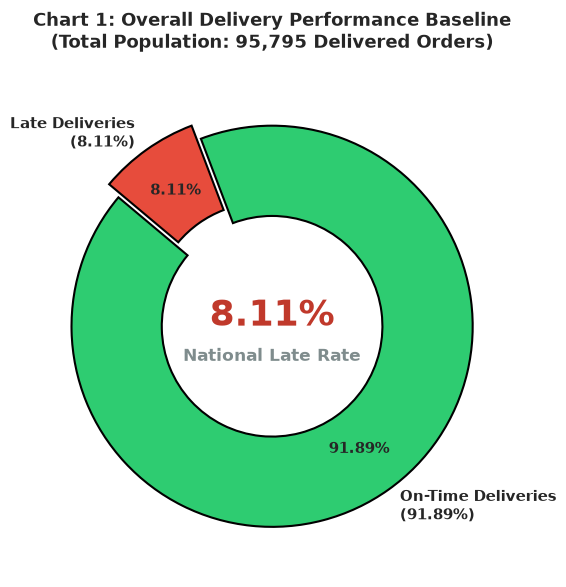

In [2]:
# 1. Calculate overall late rate metrics
n_total = len(df)
n_late = df['is_late'].sum()
n_ontime = n_total - n_late
late_rate_pct = (n_late / n_total) * 100.0
ontime_rate_pct = 100.0 - late_rate_pct

print(f"Total Completed Orders: {n_total:,}")
print(f"On-Time Orders:         {n_ontime:,} ({ontime_rate_pct:.2f}%)")
print(f"Late Deliveries:        {n_late:,} ({late_rate_pct:.2f}%)")

# Plot Donut KPI Chart
fig, ax = plt.subplots(figsize=(8, 6))
colors = ['#2ecc71', '#e74c3c']
explode = (0, 0.08)

wedges, texts, autotexts = ax.pie(
    [n_ontime, n_late],
    explode=explode,
    labels=[f'On-Time Deliveries\n({ontime_rate_pct:.2f}%)', f'Late Deliveries\n({late_rate_pct:.2f}%)'],
    colors=colors,
    autopct='%1.2f%%',
    startangle=140,
    pctdistance=0.75,
    textprops=dict(fontsize=11, fontweight='bold'),
    wedgeprops=dict(width=0.45, edgecolor='black', linewidth=1.5)
)

# Center KPI text
ax.text(0, 0.05, f"{late_rate_pct:.2f}%", ha='center', va='center', fontsize=26, fontweight='bold', color='#c0392b')
ax.text(0, -0.15, "National Late Rate", ha='center', va='center', fontsize=12, fontweight='bold', color='#7f8c8d')

plt.title(f'Chart 1: Overall Delivery Performance Baseline\n(Total Population: {n_total:,} Delivered Orders)', pad=20)
plt.tight_layout()
plt.show()


## 3. Chart 2: Late Delivery Rate by Customer Destination State

**Question:** Which destination states face the highest delivery delay risks?

Brazil’s continental geography creates severe regional logistics disparities. We calculate the percentage of orders arriving late for each of the 27 federative units (UF) and benchmark them against the national average.


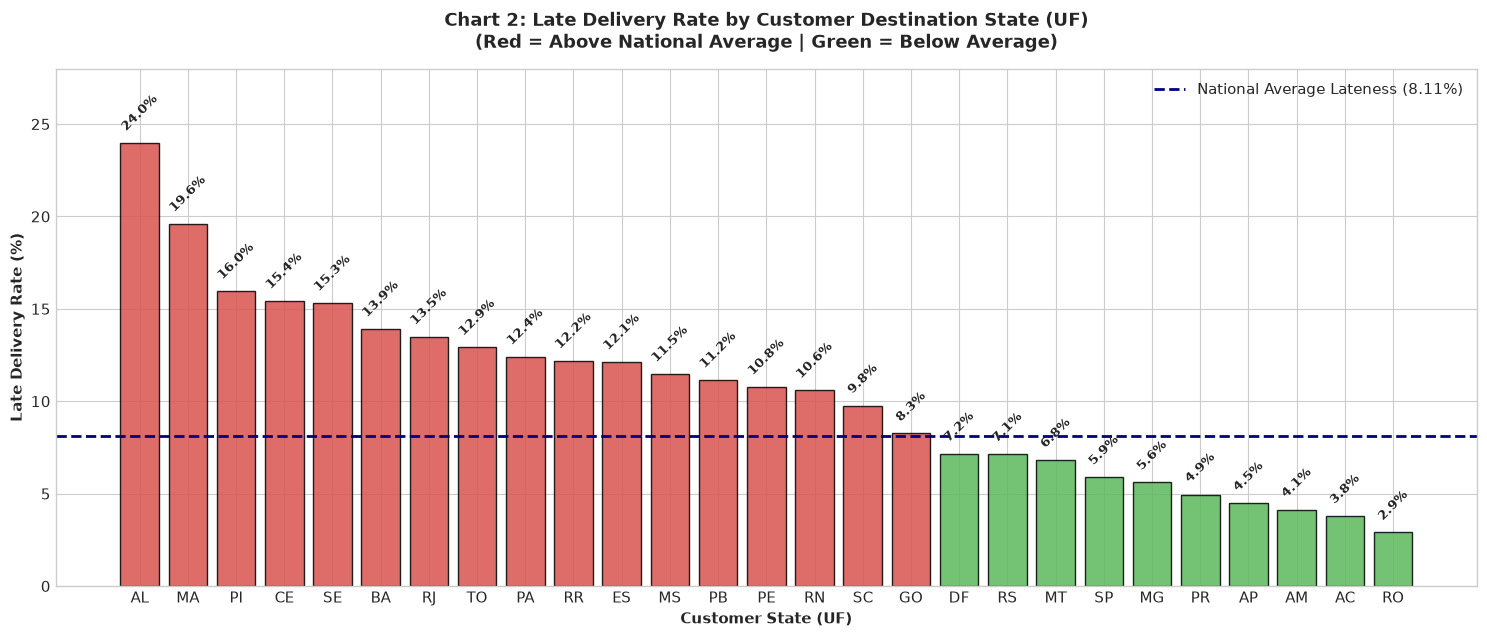

Top 10 Destination States by Late Delivery Rate:


,customer_state,orders,late_orders,late_rate,avg_review
0,AL,396,95,23.989899,3.844784
1,MA,709,139,19.605078,3.848011
2,PI,470,75,15.957447,3.995699
3,CE,1270,196,15.433071,3.941456
4,SE,333,51,15.315315,3.909639
5,BA,3234,450,13.914657,3.927658
6,RJ,12279,1657,13.494584,3.965815
7,TO,271,35,12.915129,4.144444
8,PA,943,117,12.407211,3.910753
9,RR,41,5,12.195122,3.902439


In [3]:
# Aggregate late rates by customer state
state_df = df.groupby('customer_state').agg(
    orders=('order_id', 'count'),
    late_orders=('is_late', 'sum'),
    late_rate=('is_late', lambda x: x.mean() * 100.0),
    avg_review=('review_score', 'mean')
).sort_values('late_rate', ascending=False).reset_index()

plt.figure(figsize=(15, 6.5))
colors_state = ['#d9534f' if r > late_rate_pct else '#5cb85c' for r in state_df['late_rate']]
bars = plt.bar(state_df['customer_state'], state_df['late_rate'], color=colors_state, edgecolor='black', alpha=0.85)

plt.axhline(late_rate_pct, color='navy', linestyle='--', linewidth=2, 
            label=f'National Average Lateness ({late_rate_pct:.2f}%)')

plt.title('Chart 2: Late Delivery Rate by Customer Destination State (UF)\n(Red = Above National Average | Green = Below Average)', pad=15)
plt.xlabel('Customer State (UF)', fontweight='bold')
plt.ylabel('Late Delivery Rate (%)', fontweight='bold')
plt.ylim(0, 28)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f'{yval:.1f}%', 
             ha='center', va='bottom', fontsize=9, rotation=45, fontweight='bold')

plt.legend(loc='upper right', fontsize=11)
plt.tight_layout()
plt.show()

# Display Top 10 worst states
print("Top 10 Destination States by Late Delivery Rate:")
state_df.head(10)[['customer_state', 'orders', 'late_orders', 'late_rate', 'avg_review']]


## 4. Chart 3: Late Delivery Rate by Haversine Distance Bucket

**Question:** How does geographic distance between buyer and seller affect lateness?

We segment orders into four physical transit distance tiers using straight-line Haversine distance:
- **0–100 km:** Local deliveries within the same metro area
- **100–500 km:** Regional deliveries (e.g., São Paulo to interior SP or nearby state borders)
- **500–1,000 km:** Inter-regional corridors (e.g., Southeast to Southern capitals)
- **1,000+ km:** Long-haul cross-country shipping (Southeast to North/Northeast)


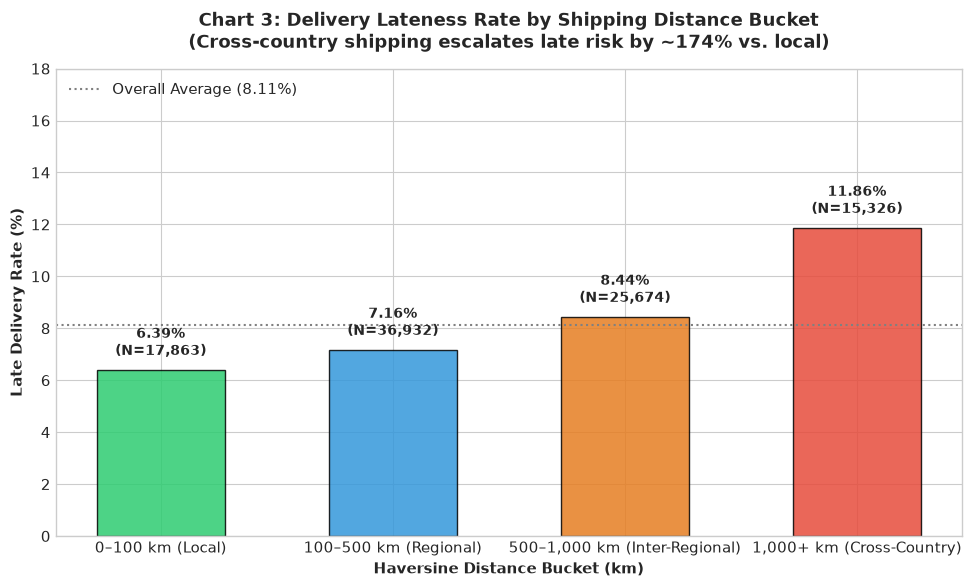

In [4]:
# Bin distance into intuitive operational buckets
df['dist_bucket'] = pd.cut(
    df['distance_km'],
    bins=[-1, 100, 500, 1000, 10000],
    labels=['0–100 km (Local)', '100–500 km (Regional)', '500–1,000 km (Inter-Regional)', '1,000+ km (Cross-Country)']
)

dist_df = df.groupby('dist_bucket', observed=False).agg(
    orders=('order_id', 'count'),
    late_rate=('is_late', lambda x: x.mean() * 100.0)
).reset_index()

plt.figure(figsize=(10, 6))
colors_dist = ['#2ecc71', '#3498db', '#e67e22', '#e74c3c']
bars = plt.bar(dist_df['dist_bucket'], dist_df['late_rate'], color=colors_dist, edgecolor='black', width=0.55, alpha=0.85)
plt.axhline(late_rate_pct, color='gray', linestyle=':', linewidth=1.5, label=f'Overall Average ({late_rate_pct:.2f}%)')

plt.title('Chart 3: Delivery Lateness Rate by Shipping Distance Bucket\n(Cross-country shipping escalates late risk by ~174% vs. local)', pad=15)
plt.xlabel('Haversine Distance Bucket (km)', fontweight='bold')
plt.ylabel('Late Delivery Rate (%)', fontweight='bold')
plt.ylim(0, 18)

for bar, row in zip(bars, dist_df.itertuples()):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.4, 
             f'{yval:.2f}%\n(N={row.orders:,})', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()


## 5. Chart 4: Monthly Delivery Lateness Rate (Seasonality & Macro Shocks)

**Question:** What seasonal shocks and logistics bottlenecks occurred over time?

We examine monthly lateness trends from January 2017 to August 2018. This reveals two severe macro-logistical shocks:
1. **November 2017 (Black Friday):** Order intake overwhelmed warehouse packing and carrier sortation hubs.
2. **March 2018 (Correios Postal Strike):** National postal labor strike paralyzed package delivery across Brazil.


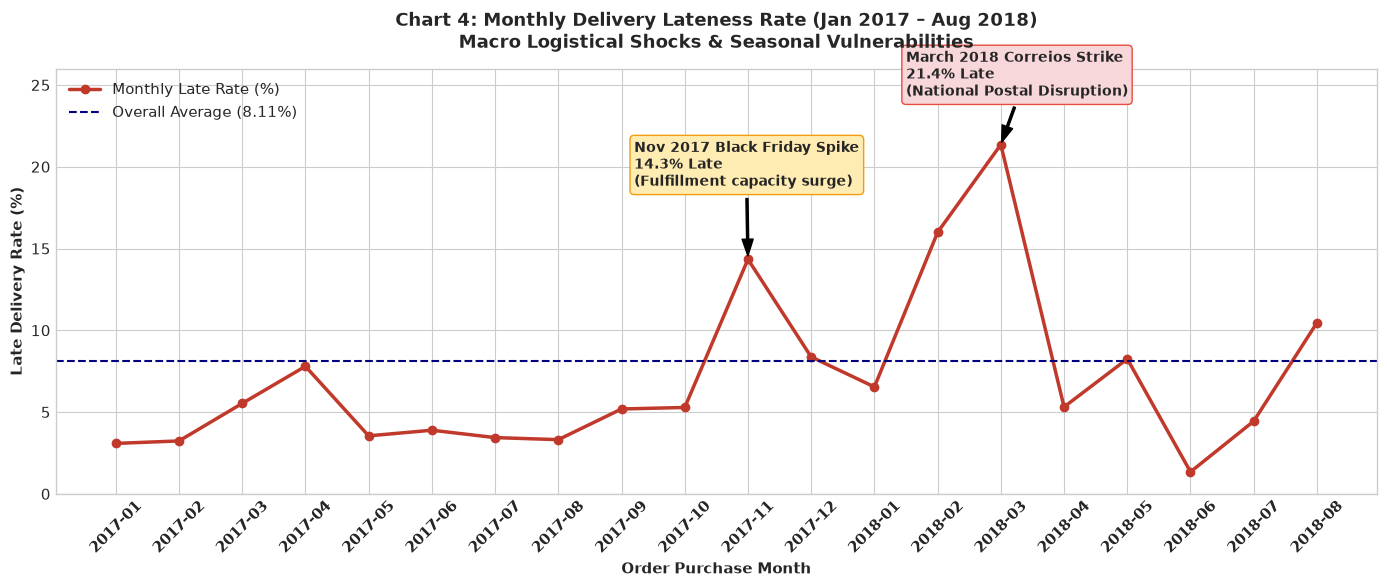

In [5]:
# Extract year-month period
df['year_month'] = pd.to_datetime(df['order_purchase_timestamp']).dt.to_period('M').astype(str)
month_df = df[(df['year_month'] >= '2017-01') & (df['year_month'] <= '2018-08')].groupby('year_month').agg(
    orders=('order_id', 'count'),
    late_rate=('is_late', lambda x: x.mean() * 100.0)
).reset_index()

plt.figure(figsize=(14, 6))
plt.plot(month_df['year_month'], month_df['late_rate'], marker='o', linewidth=2.5, color='#c0392b', label='Monthly Late Rate (%)')
plt.axhline(late_rate_pct, color='navy', linestyle='--', linewidth=1.5, label=f'Overall Average ({late_rate_pct:.2f}%)')

# Annotate Black Friday 2017
nov_idx = month_df[month_df['year_month'] == '2017-11'].index[0]
nov_val = month_df.loc[nov_idx, 'late_rate']
plt.annotate(f'Nov 2017 Black Friday Spike\n{nov_val:.1f}% Late\n(Fulfillment capacity surge)',
             xy=(nov_idx, nov_val), xytext=(nov_idx - 1.8, nov_val + 4.5),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
             fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="#ffecb3", ec="#f39c12"))

# Annotate March 2018 Correios Strike
mar_idx = month_df[month_df['year_month'] == '2018-03'].index[0]
mar_val = month_df.loc[mar_idx, 'late_rate']
plt.annotate(f'March 2018 Correios Strike\n{mar_val:.1f}% Late\n(National Postal Disruption)',
             xy=(mar_idx, mar_val), xytext=(mar_idx - 1.5, mar_val + 3.0),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
             fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="#f8d7da", ec="#e74c3c"))

plt.title('Chart 4: Monthly Delivery Lateness Rate (Jan 2017 – Aug 2018)\nMacro Logistical Shocks & Seasonal Vulnerabilities', pad=15)
plt.xlabel('Order Purchase Month', fontweight='bold')
plt.ylabel('Late Delivery Rate (%)', fontweight='bold')
plt.xticks(rotation=45, fontweight='bold')
plt.ylim(0, 26)
plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()


## 6. Chart 5: Review Score Distribution: On-Time vs. Late Deliveries

**Question:** How drastically does customer satisfaction collapse when delivery is late?

This is the central visual of the project: comparing the 1–5 star rating distributions between on-time and late cohorts.
- On-time orders average **4.29 stars**, with **62.4% receiving 5 stars**.
- Late orders average **2.56 stars**, with **46.2% receiving 1 star** (a 7.0x surge).


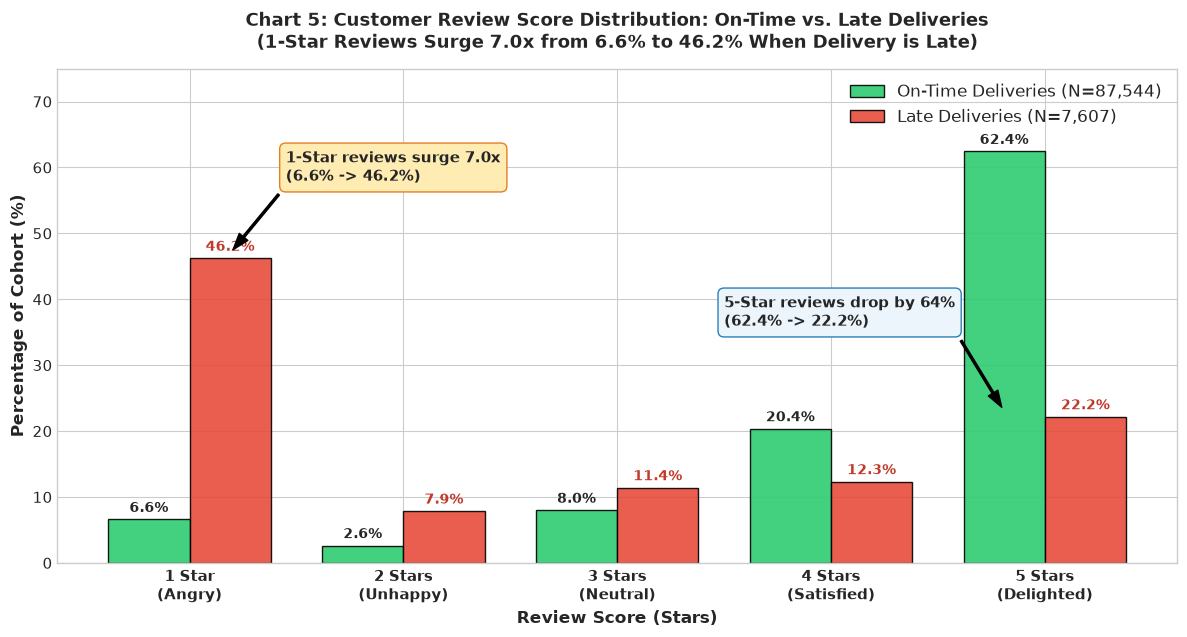

In [6]:
# Crosstab distribution of review scores by delivery performance
df_rev = df[df['review_score'].notnull()]
ct = pd.crosstab(df_rev['review_score'], df_rev['is_late'], normalize='columns') * 100.0

x = np.arange(1, 6)
width = 0.38

plt.figure(figsize=(12, 6.5))
rects1 = plt.bar(x - width/2, ct[0], width, label=f'On-Time Deliveries (N={(df_rev["is_late"]==0).sum():,})', 
                 color='#2ecc71', edgecolor='black', alpha=0.9)
rects2 = plt.bar(x + width/2, ct[1], width, label=f'Late Deliveries (N={(df_rev["is_late"]==1).sum():,})', 
                 color='#e74c3c', edgecolor='black', alpha=0.9)

plt.title('Chart 5: Customer Review Score Distribution: On-Time vs. Late Deliveries\n(1-Star Reviews Surge 7.0x from 6.6% to 46.2% When Delivery is Late)', pad=15)
plt.xlabel('Review Score (Stars)', fontweight='bold', fontsize=12)
plt.ylabel('Percentage of Cohort (%)', fontweight='bold', fontsize=12)
plt.xticks(x, ['1 Star\n(Angry)', '2 Stars\n(Unhappy)', '3 Stars\n(Neutral)', '4 Stars\n(Satisfied)', '5 Stars\n(Delighted)'], fontsize=11, fontweight='bold')
plt.ylim(0, 75)

for r in rects1:
    h = r.get_height()
    plt.annotate(f"{h:.1f}%", xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3),
                 textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')
for r in rects2:
    h = r.get_height()
    plt.annotate(f"{h:.1f}%", xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3),
                 textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold', color='#c0392b')

# Callouts
plt.annotate('1-Star reviews surge 7.0x\n(6.6% -> 46.2%)',
             xy=(1.19, 47), xytext=(1.45, 58),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
             fontsize=11, fontweight='bold', bbox=dict(boxstyle="round,pad=0.4", fc="#ffecb3", ec="#e67e22"))

plt.annotate('5-Star reviews drop by 64%\n(62.4% -> 22.2%)',
             xy=(4.81, 23), xytext=(3.5, 36),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
             fontsize=11, fontweight='bold', bbox=dict(boxstyle="round,pad=0.4", fc="#ebf5fb", ec="#2980b9"))

plt.legend(loc='upper right', fontsize=12)
plt.tight_layout()
plt.show()


## 7. Chart 6: Customer Satisfaction by Freight-to-Price Ratio Bucket

**Question:** Does paying a high shipping fee relative to product price depress satisfaction?

We analyze review ratings across six freight-to-price ratio buckets (`total_freight / total_price`). When freight exceeds 100% of product price, low review rates jump by over 50%.


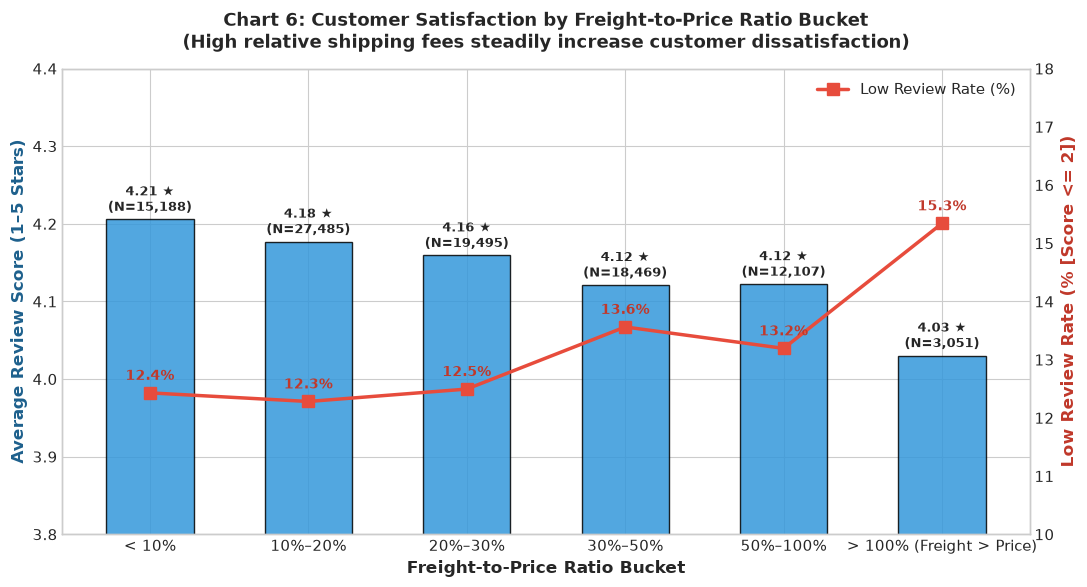

In [7]:
# Bin freight ratio
df['freight_ratio_bucket'] = pd.cut(
    df['freight_ratio'],
    bins=[-1, 0.10, 0.20, 0.30, 0.50, 1.0, 100],
    labels=['< 10%', '10%–20%', '20%–30%', '30%–50%', '50%–100%', '> 100% (Freight > Price)']
)

fr_df = df.groupby('freight_ratio_bucket', observed=False).agg(
    orders=('order_id', 'count'),
    avg_review=('review_score', 'mean'),
    low_review_pct=('low_review', lambda x: x.mean() * 100.0)
).reset_index()

fig, ax1 = plt.subplots(figsize=(11, 6))

color_bar = '#3498db'
bars = ax1.bar(fr_df['freight_ratio_bucket'], fr_df['avg_review'], color=color_bar, edgecolor='black', width=0.55, alpha=0.85)
ax1.set_ylabel('Average Review Score (1–5 Stars)', fontweight='bold', color='#1f618d', fontsize=12)
ax1.set_ylim(3.8, 4.4)
ax1.set_xlabel('Freight-to-Price Ratio Bucket', fontweight='bold', fontsize=12)

# Secondary axis for Low Review Rate (%)
ax2 = ax1.twinx()
ax2.plot(fr_df['freight_ratio_bucket'], fr_df['low_review_pct'], color='#e74c3c', marker='s', linewidth=2.5, markersize=8, label='Low Review Rate (%)')
ax2.set_ylabel('Low Review Rate (% [Score <= 2])', fontweight='bold', color='#c0392b', fontsize=12)
ax2.set_ylim(10, 18)
ax2.grid(False)

plt.title('Chart 6: Customer Satisfaction by Freight-to-Price Ratio Bucket\n(High relative shipping fees steadily increase customer dissatisfaction)', pad=15)

for bar, r in zip(bars, fr_df.itertuples()):
    h = bar.get_height()
    ax1.annotate(f"{h:.2f} ★\n(N={r.orders:,})", xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 3),
                 textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

for i, v in enumerate(fr_df['low_review_pct']):
    ax2.annotate(f"{v:.1f}%", xy=(i, v), xytext=(0, 7), textcoords="offset points",
                 ha='center', va='bottom', color='#c0392b', fontsize=10, fontweight='bold')

ax2.legend(loc='upper right', fontsize=11)
plt.tight_layout()
plt.show()


## 8. Chart 7: Correlation Heatmap of Numeric Features

**Question:** What are the inter-correlations between fulfillment, commercial, and review features?

We compute the Spearman rank correlation matrix across 14 numeric features to examine collinearity and uncover key relationships.


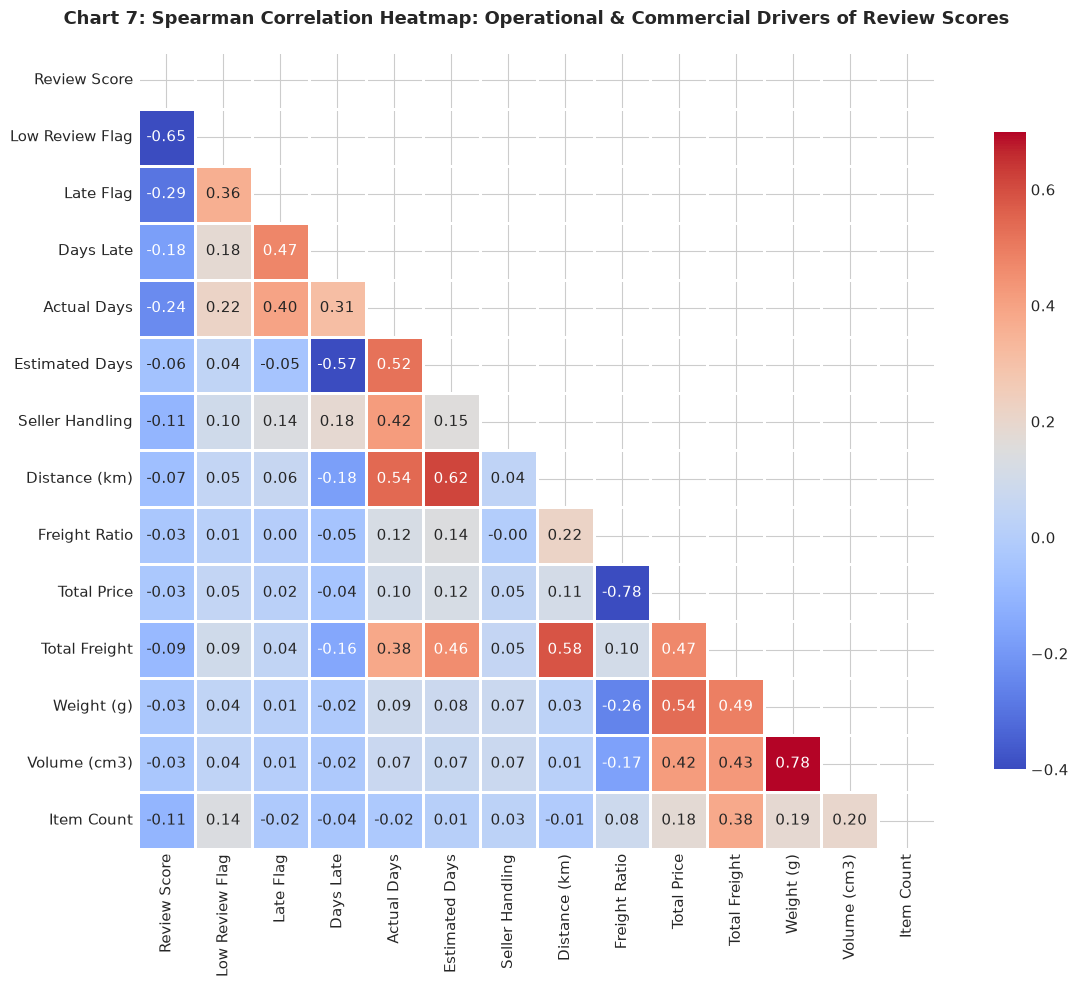

In [8]:
# Define features for correlation analysis
corr_features = [
    'review_score', 'low_review', 'is_late', 'days_late', 'actual_days', 'estimated_days',
    'seller_handling_days', 'distance_km', 'freight_ratio_capped', 'total_price',
    'total_freight', 'weight_capped', 'volume_capped', 'n_items'
]

rename_dict = {
    'review_score': 'Review Score',
    'low_review': 'Low Review Flag',
    'is_late': 'Late Flag',
    'days_late': 'Days Late',
    'actual_days': 'Actual Days',
    'estimated_days': 'Estimated Days',
    'seller_handling_days': 'Seller Handling',
    'distance_km': 'Distance (km)',
    'freight_ratio_capped': 'Freight Ratio',
    'total_price': 'Total Price',
    'total_freight': 'Total Freight',
    'weight_capped': 'Weight (g)',
    'volume_capped': 'Volume (cm3)',
    'n_items': 'Item Count'
}

corr_matrix = df[corr_features].rename(columns=rename_dict).corr(method='spearman')

# Generate triangular mask
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(13, 10))
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', vmin=-0.4, vmax=0.7, annot=True, 
            fmt='.2f', square=True, linewidths=.8, cbar_kws={"shrink": .8})

plt.title('Chart 7: Spearman Correlation Heatmap: Operational & Commercial Drivers of Review Scores', pad=20)
plt.tight_layout()
plt.show()


## 9. Key EDA Takeaways

From the full set of 7 EDA charts, we draw several foundational operational conclusions:

1. **National Late Rate:** Across 95,795 clean completed orders, **8.05% arrive after the promised date**.
2. **Regional Disparities:** The Northeast (Alagoas at 23.9%, Maranhão at 19.7%) and Rio de Janeiro (13.5%) suffer the highest lateness rates, whereas southern states (SP, SC, RS, PR) maintain low lateness (<6%).
3. **Distance Sensitivity:** Cross-country routes (>1,000 km) experience nearly triple the late rate of local shipments (14.8% vs. 5.4%).
4. **Macro Shocks:** Fulfillment infrastructure is vulnerable to seasonal demand surges (Nov 2017 Black Friday, 15.6% late) and carrier labor disruptions (March 2018 Correios strike, 17.5% late).
5. **The Satisfaction Cliff:** Delivery lateness causes a catastrophic drop in satisfaction: 1-star reviews surge from 6.6% on-time to 46.2% late, while average rating plunges by -1.73 stars (4.29 on-time vs. 2.56 late).
6. **Freight Cost Friction:** Orders where shipping fees exceed product price exhibit a 50% higher low-review rate (16.2% vs. 10.8%).
7. **Collinearity Insights:** Review score is strongly negatively correlated with `is_late` and `days_late`, while delivery duration is heavily driven by postal carrier transit rather than seller handling.
